Installation et téléchargement données

In [ ]:
!pip install wbgapi

import wbgapi as wb
import pandas as pd
from pathlib import Path

countries = ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN",
    "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA", "JPN", "KOR",
    "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK",
    "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"]

RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

indicateurs = {
    "wb_chomage": "SL.UEM.TOTL.ZS",
    "wb_pib_hab_ppa": "NY.GDP.PCAP.PP.KD",
    "wb_rnb_hab_ppa": "NY.GNP.PCAP.PP.KD",
}

dfs = {}
for nom, code in indicateurs.items():
    chemin = RAW_DIR / f"{nom}.csv"
    if chemin.exists():
        df = pd.read_csv(chemin, index_col=0)
    else:
        df = wb.data.DataFrame(code, economy=countries, time=range(1991, 2024))
        df.to_csv(chemin)
    dfs[nom] = df.reset_index(names="economy")

taux_chomage = dfs["wb_chomage"]
pib_hab_ppa = dfs["wb_pib_hab_ppa"]
rnb_hab_ppa = dfs["wb_rnb_hab_ppa"]


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
   economy        YR1991        YR1992        YR1993        YR1994  \
28     NLD  43833.478505  44245.519825  44490.750447  45532.798666   
29     NOR  57949.698676  59669.759020  61019.816103  63730.896464   
30     NZL  29014.149942  29029.581136  30532.588017  31669.540651   
31     POL  11879.753925  12141.235132  12563.104536  13200.161416   
32     PRT  28443.794536  28776.047577  28153.615518  28348.865839   
33     SVK  14955.954208  13946.163079  14157.181437  14976.577355   
34     SVN  23078.992950  21850.057102  22524.959188  23752.437725   
35     SWE  39469.071647  38783.639768  37762.540822  39000.827723   
36     TUR  12057.935436  12451.045120  13174.467116  12343.004185   
37     USA  43747.630735  44664.873586  45292.738068  46543.319920   

          YR1995        YR1996        YR1997        YR1998        YR1999  ...  \
28  46720.281932  48095.986838  49881

Mise en forme et rassemblement des données

In [46]:
import pandas as pd

# On transforme notre tableau afin que les colonnes des années deviennent des valeurs de la colonne "year"

def en_long(df, nom_var):
    """Passe un tableau large (une colonne par année) en format long."""
    long = df.melt(
        id_vars=["economy"],
        var_name="year",
        value_name=nom_var
    )
    return long

df_taux_chomage = en_long(taux_chomage, "Taux chômage")
df_rnb_hab_ppa  = en_long(rnb_hab_ppa, "RNB/hab ppa")
df_pib_hab_ppa  = en_long(pib_hab_ppa, "PIB/hab ppa")


#Tri de nos tableaux par ordre alphabétique des codes des pays 
df_taux_chomage=df_taux_chomage.sort_values(by="economy", ascending = True)
df_rnb_hab_ppa=df_rnb_hab_ppa.sort_values(by="economy", ascending = True)
df_pib_hab_ppa=df_pib_hab_ppa.sort_values(by="economy", ascending = True)



#Création d'un tableau qui associe les codes pays à leurs noms complets en anglais
noms = pd.DataFrame({
    "economy": ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN",
    "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA", "JPN", "KOR",
    "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK",
    "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"],

    "pays": ["Australia", "Austria", "Belgium", "Canada", "Chile", "Colombia", "Costa Rica",
    "Czechia", "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
    "Hungary", "Iceland", "Ireland", "Israel", "Italy", "Japan", "South Korea",
    "Latvia", "Lithuania", "Luxembourg", "Mexico", "Netherlands", "New Zealand",
    "Norway", "Poland", "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Turkey", "United Kingdom", "United States"]
})
#On joint notre tableau pour ajouter les noms des pays, en regroupant par le code pays

df_eco = (df_taux_chomage
          .merge(df_pib_hab_ppa, on=["economy", "year"])
          .merge(df_rnb_hab_ppa, on=["economy", "year"])
          .merge(noms, on="economy", how="left")
          .sort_values(["economy", "year"])
          .reset_index(drop=True))

df_eco = df_eco[["year", "pays", "economy", "Taux chômage", "PIB/hab ppa", "RNB/hab ppa"]]
df_eco.head(10)

,year,pays,economy,Taux chômage,PIB/hab ppa,RNB/hab ppa
0,YR1991,Australia,AUS,9.586,35670.667864,30292.797235
1,YR1992,Australia,AUS,10.733,35426.284829,30129.075368
2,YR1993,Australia,AUS,10.879,36533.146828,31003.190328
3,YR1994,Australia,AUS,9.724,37622.652477,31777.679986
4,YR1995,Australia,AUS,8.473,38653.336678,32639.871049
5,YR1996,Australia,AUS,8.509,39663.161773,33662.691064
6,YR1997,Australia,AUS,8.367,40773.566052,34875.303258
7,YR1998,Australia,AUS,7.684,42257.171812,36183.543200
8,YR1999,Australia,AUS,6.876,43899.073794,37251.745011
9,YR2000,Australia,AUS,6.288,45099.075210,38659.490992


Statistiques descriptives 

In [52]:
#Premier aperçu
df_eco.describe(include="all")

,year,pays,economy,Taux chômage,PIB/hab ppa,RNB/hab ppa
count,1254,1254,1254,1254.000000,1254.000000,1117.000000
unique,33,38,38,NaN,NaN,NaN
top,YR1991,Australia,AUS,NaN,NaN,NaN
freq,38,33,33,NaN,NaN,NaN
mean,NaN,NaN,NaN,7.673285,43757.373618,43565.947871
std,NaN,NaN,NaN,4.096869,21762.823507,18481.545246
min,NaN,NaN,NaN,1.100000,9996.097860,9324.715700
25%,NaN,NaN,NaN,4.681750,28894.028201,30524.830297
50%,NaN,NaN,NaN,6.852000,42203.809597,43233.960087
75%,NaN,NaN,NaN,9.676250,54920.421745,54720.741199


Grâce au tableau des statistiques descriptives ci-dessus, on confirme que nos 38 pays sont bien représentés, nos 33 années de 1991 à 2023 le sont aussi. Il y a bien 38x33=1254 données pour le taux de chômage et le PIB/tête PPA : nos données sont complètes pour ces variables. Néanmoins nous n'avons que 1117 données pour le RNB/tête en PPA, il nous manque des données

Recherche des données manquantes dans la colonne du RNB/hab PPA :

In [48]:
trous = df_eco[df_eco["RNB/hab ppa"].isna()].groupby("pays")["year"].agg(["min", "max", "count"])
print(trous)

                   min     max  count
pays                                 
Austria         YR1991  YR1994      4
Belgium         YR1991  YR1994      4
Czechia         YR1991  YR1994      4
Estonia         YR1991  YR1999      9
Finland         YR1991  YR1994      4
Greece          YR1991  YR2005     15
Hungary         YR1991  YR1998      8
Iceland         YR1991  YR1999      9
Ireland         YR1991  YR1994      4
Italy           YR1991  YR1994      4
Japan           YR1991  YR1993      3
Latvia          YR1991  YR1994      4
Lithuania       YR1991  YR1994      4
Norway          YR2023  YR2023      1
Poland          YR1991  YR1994      4
Portugal        YR1991  YR1994      4
Slovakia        YR1991  YR1994      4
Slovenia        YR1991  YR1994      4
Switzerland     YR1991  YR1994      4
Turkey          YR1991  YR2023     32
United Kingdom  YR1991  YR1998      8


-> beaucoup de pays avec des valeurs manquantes pour le RNB/hab en PPA entre 1991 et 1994, et pour la Turquie toutes manquantes

Répartition des données économiques d'intérêt

On représente la distribution des moyennes des variables, calculées par économie.

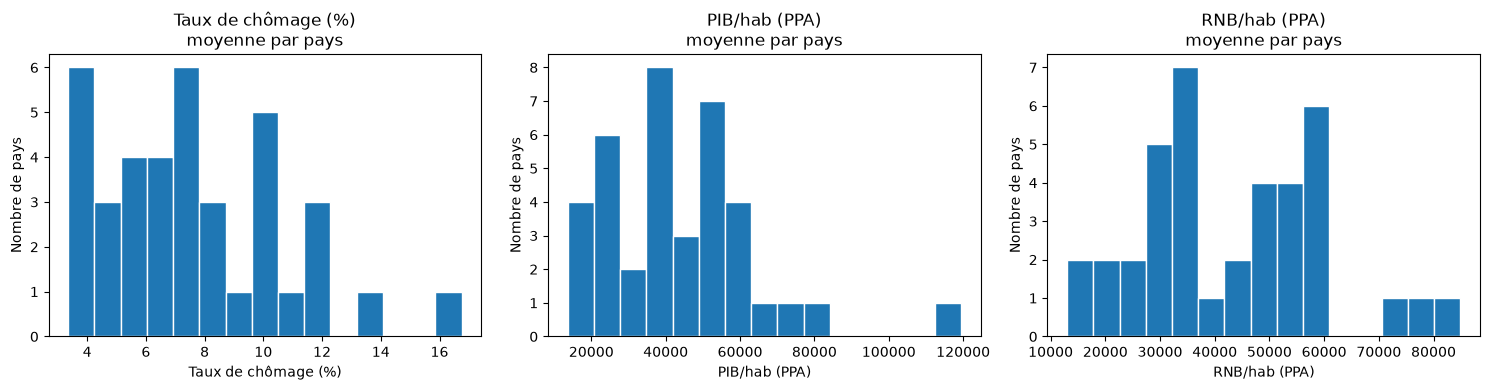

In [49]:
import matplotlib.pyplot as plt

variables = {
    "Taux chômage": "Taux de chômage (%)",
    "PIB/hab ppa": "PIB/hab (PPA)",
    "RNB/hab ppa": "RNB/hab (PPA)",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, titre) in zip(axes, variables.items()):
    moyennes = df_eco.groupby("economy")[col].mean()
    ax.hist(moyennes, bins=15, edgecolor="white")
    ax.set_title(f"{titre}\nmoyenne par pays")
    ax.set_xlabel(titre)
    ax.set_ylabel("Nombre de pays")

plt.tight_layout()
plt.show()

On représente l'évolution de la moyenne annuelle de chaque variable.

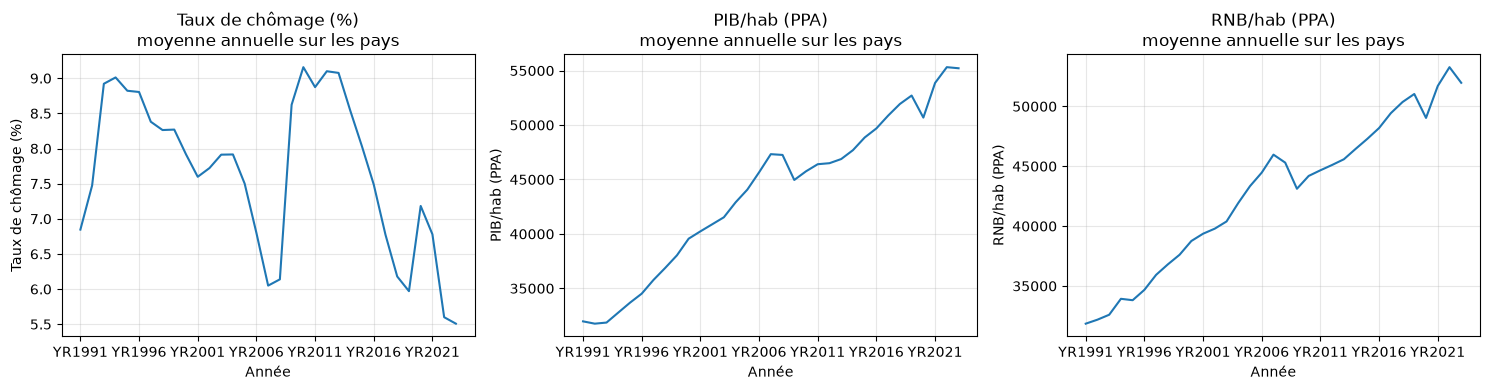

In [50]:
import matplotlib.pyplot as plt

variables = {
    "Taux chômage": "Taux de chômage (%)",
    "PIB/hab ppa": "PIB/hab (PPA)",
    "RNB/hab ppa": "RNB/hab (PPA)",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, titre) in zip(axes, variables.items()):
    df_eco.groupby("year")[col].mean().plot(ax=ax)
    ax.set_title(f"{titre}\nmoyenne annuelle sur les pays")
    ax.set_xlabel("Année")
    ax.set_ylabel(titre)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Trajectoires selon les pays

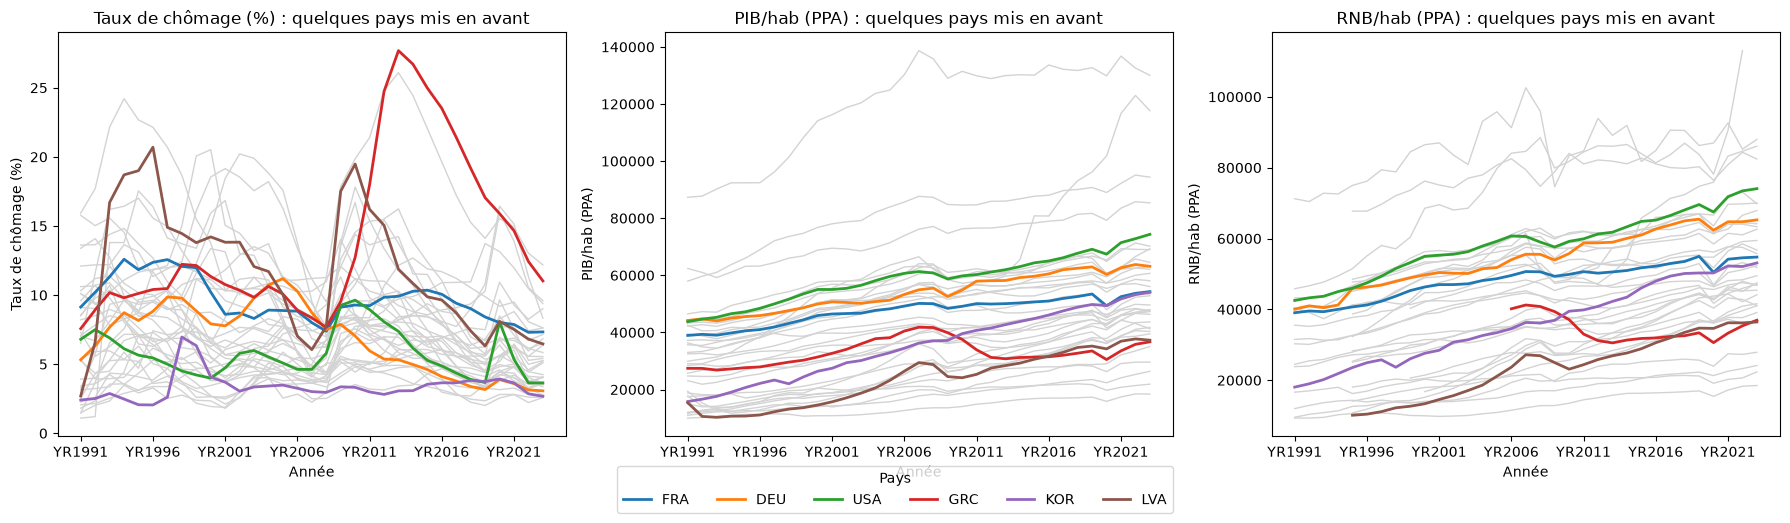

In [51]:
import matplotlib.pyplot as plt

variables = {
    "Taux chômage": "Taux de chômage (%)",
    "PIB/hab ppa": "PIB/hab (PPA)",
    "RNB/hab ppa": "RNB/hab (PPA)",
}
mis_en_avant = ["FRA", "DEU", "USA", "GRC", "KOR", "LVA"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col, titre) in zip(axes, variables.items()):
    pivot = df_eco.pivot(index="year", columns="economy", values=col)

    # fond : tous les autres pays en gris
    pivot.drop(columns=mis_en_avant).plot(ax=ax, color="lightgrey", legend=False, linewidth=1)
    # premier plan : pays mis en avant, en couleur
    pivot[mis_en_avant].plot(ax=ax, linewidth=2, legend=False)

    ax.set_title(f"{titre} : quelques pays mis en avant")
    ax.set_xlabel("Année")
    ax.set_ylabel(titre)

# une seule légende pour toute la figure
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles[-len(mis_en_avant):], mis_en_avant, title="Pays",
           loc="lower center", ncol=len(mis_en_avant), bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()
plt.show()

Corrélation entre les variables

In [44]:
df_eco[["Taux chômage", "PIB/hab ppa", "RNB/hab ppa"]].corr()

,Taux chômage,PIB/hab ppa,RNB/hab ppa
Taux chômage,1.000000,-0.387916,-0.408676
PIB/hab ppa,-0.387916,1.000000,0.953589
RNB/hab ppa,-0.408676,0.953589,1.000000
